# 01. Exploratory data analysis of train / Разведочный анализ данных train

**EN.** Exploratory analysis of the training data: the sample, missing values, outliers, the distributions of the selected features for loans with and without an event, and what the preprocessing changes in the data. **Descriptive only.** The substantive data checks (events by sample, leakage, PSI, LGD) were done in stage 1 before any model (`reports/data_audit/stage1_data_audit.md`, notebook `00`); this notebook adds figures and the outlier analysis after stage 3 and changes neither the features nor the models. Only **train** is used (observation dates 2013-03 … 2015-06, the 15 % loan sample, Y1 population: current at *t*, no default before *t*); validation and test are not read. Figures are saved to `reports/data_audit/eda/figures/`, tables to `reports/data_audit/eda/`.

**RU.** Разведочный анализ обучающих данных: выборка, пропуски, выбросы, распределения отобранных признаков у кредитов с событием и без, и что меняет в данных предобработка. **Только описание.** Содержательные проверки данных (события по выборкам, утечка, PSI, LGD) сделаны на этапе 1 до построения моделей (`reports/data_audit/stage1_data_audit.md`, ноутбук `00`); этот ноутбук добавляет графики и анализ выбросов после этапа 3 и не меняет ни признаки, ни модели. Используется только **train** (даты наблюдения 2013-03 … 2015-06, 15 %-я выборка кредитов, популяция Y1: без просрочки на *t* и без дефолта до *t*); validation и test не читаются. Графики сохраняются в `reports/data_audit/eda/figures/`, таблицы — в `reports/data_audit/eda/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import json
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from xai_ews.config import feature_config
from xai_ews.data.dictionary import feature_dictionary
from xai_ews.data.panel import prepare_monthly, scan_panel
from xai_ews.models.scorecard import binners
from xai_ews.paths import DATA_AUDIT_DIR, INTERIM_DIR, PANEL_DIR

OUT = DATA_AUDIT_DIR / "eda"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 20261025
SEL = feature_config()["selected"]
FEATS, CATS = SEL["features"], SEL["categorical"]
NUM = [f for f in FEATS if f not in CATS]
FD = feature_dictionary()
CANDS = FD["feature"].tolist()
SHORT = {"borrower_credit_score_at_origination": "FICO", "co_borrower_credit_score_at_origination": "FICO co-borrower",
         "debt_to_income_dti": "DTI", "original_interest_rate": "interest rate", "original_upb": "original UPB",
         "mortgage_insurance_percentage": "MI %", "first_time_home_buyer_indicator": "first-time buyer",
         "hpi_chg_since_orig_rel_us": "HPI change rel. US", "excess_principal_12m": "excess principal 12m"}
short = lambda f: SHORT.get(f, f)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

# train rows of the Y1 population with an observed label
pop = scan_panel().filter((pl.col("split_main") == "train") & pl.col("pop_y1") & pl.col("y1").is_not_null())
df = pop.select("loan_identifier", "m", "obs_date", "vintage", "y1", "upb_masked", *FEATS).collect()
print(df.height, "rows,", df["loan_identifier"].n_unique(), "loans,", int(df["y1"].sum()), "events")

1710613 rows, 304852 loans, 2089 events


### 1. The sample / Выборка

**EN.** Size of the sample and the event rate by observation date and by vintage (the quarter of origination).

**RU.** Размер выборки и доля событий по дате наблюдения и по поколению (кварталу выдачи).

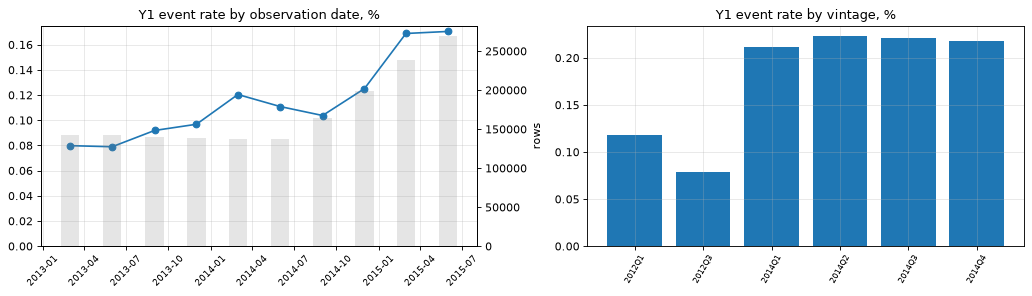

,value
rows,"1,710,613.0000"
loans,"304,852.0000"
events,"2,089.0000"
loans with an event,"1,037.0000"
"event rate, %",0.1221
snapshots per loan,5.6113


,obs_date,rows,events,rate_pct
0,2013-03-01,142807,114,0.0798
1,2013-06-01,143103,113,0.0790
2,2013-09-01,140391,129,0.0919
3,2013-12-01,138411,134,0.0968
4,2014-03-01,136986,165,0.1205
5,2014-06-01,137990,153,0.1109
6,2014-09-01,164796,171,0.1038
7,2014-12-01,198965,249,0.1251
8,2015-03-01,238005,402,0.1689
9,2015-06-01,269159,459,0.1705


In [2]:
y = df["y1"].to_numpy()
overview = pd.Series({"rows": df.height, "loans": df["loan_identifier"].n_unique(), "events": int(y.sum()),
                      "loans with an event": df.filter(pl.col("y1") == 1)["loan_identifier"].n_unique(),
                      "event rate, %": 100 * y.mean(), "snapshots per loan": df.height / df["loan_identifier"].n_unique()})
by_date = (df.group_by("obs_date").agg(pl.len().alias("rows"), pl.col("y1").sum().alias("events"),
                                      (100 * pl.col("y1").mean()).alias("rate_pct")).sort("obs_date").to_pandas())
by_vint = (df.group_by("vintage").agg(pl.len().alias("rows"), pl.col("y1").sum().alias("events"),
                                     (100 * pl.col("y1").mean()).alias("rate_pct")).sort("vintage").to_pandas())
by_date.to_csv(OUT / "eda_by_date.csv", index=False)
by_vint.to_csv(OUT / "eda_by_vintage.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(by_date["obs_date"], by_date["rate_pct"], marker="o")
ax[0].set_title("Y1 event rate by observation date, %"); ax[0].set_ylim(0, None); ax[0].tick_params(axis="x", rotation=45, labelsize=8)
ax2 = ax[0].twinx(); ax2.bar(by_date["obs_date"], by_date["rows"], width=40, alpha=0.2, color="grey"); ax2.set_ylabel("rows"); ax2.grid(False)
ax[1].bar(by_vint["vintage"], by_vint["rate_pct"])
ax[1].set_title("Y1 event rate by vintage, %"); ax[1].tick_params(axis="x", rotation=60, labelsize=7)
plt.tight_layout(); save(fig, "01_sample"); plt.show()
display(overview.to_frame("value"))
by_date

**EN. How to read.** Train has 1,710,613 observations of 304,852 loans (5.6 quarterly snapshots per loan) and 2,089 events on 1,037 loans: 0.12 %, about one event per 820 observations. The rate rises from 0.08 % in 2013 to 0.17 % in 2015. In 2013 the sample consists of the 2012 vintages (post-crisis loans, many refinancings; 0.08–0.12 %); from late 2014 the 2014 vintages enter (a loan enters the panel at age 6 months) with a rate of about 0.22 %. So the event rate depends on the vintage mix, which is why loan age and the origination features matter. With one event per 820 rows, accuracy says nothing (a model that never alerts is right 99.88 % of the time); the models are judged by AUC, PR-AUC and the precision and recall of the alert list.

**RU. Как читать.** В train 1 710 613 наблюдений 304 852 кредитов (5,6 квартальных снимка на кредит) и 2 089 событий на 1 037 кредитах: 0,12 %, примерно одно событие на 820 наблюдений. Доля событий растёт с 0,08 % в 2013 г. до 0,17 % в 2015 г. В 2013 г. выборка состоит из поколений 2012 г. (послекризисные кредиты, много рефинансирований; 0,08–0,12 %), с конца 2014 г. в неё входят поколения 2014 г. (кредит попадает в панель в возрасте 6 месяцев) с долей около 0,22 %. Значит, доля событий зависит от состава поколений, и поэтому важны возраст кредита и признаки на дату выдачи. При одном событии на 820 строк accuracy ничего не говорит (модель, которая никогда не поднимает тревогу, права в 99,88 % случаев); модели оцениваются по AUC, PR-AUC, точности и полноте списка тревог.

### 2. Missing values / Пропуски

**EN.** Share of missing values for each of the 59 candidates on the train population, and the event rate of the rows where the value is missing vs present. How missing values are handled (no imputation anywhere): CatBoost, XGBoost and LightGBM split on missing values natively; the scorecard B0 puts missing values into a WoE bin of their own or merges them with the closest bin; the MLP replaces a missing number with 0 and adds a 0/1 indicator.

**RU.** Доля пропусков по каждому из 59 кандидатов на популяции train и доля событий в строках с пропуском и без. Как обрабатываются пропуски (нигде ничего не заполняется «средним»): CatBoost, XGBoost и LightGBM сами разбивают по пропуску; скоринговая карта B0 относит пропуск в отдельную корзину WoE или объединяет с ближайшей; MLP заменяет пропущенное число на 0 и добавляет индикатор 0/1.

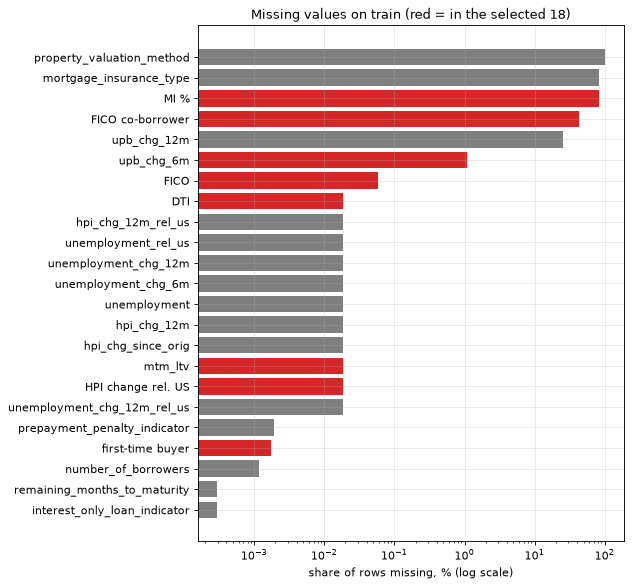

36 of 59 candidates have no missing values


,feature,selected,group,missing_rows,missing_pct,rate_if_missing_pct,rate_if_present_pct
0,property_valuation_method,False,loan,1710613,100.0000,0.1221,NaN
1,mortgage_insurance_type,False,loan,1422592,83.1627,0.1045,0.2094
2,mortgage_insurance_percentage,True,loan,1422592,83.1627,0.1045,0.2094
3,co_borrower_credit_score_at_origination,True,borrower,733870,42.9010,0.2094,0.0565
4,upb_chg_12m,False,behaviour,433212,25.3250,0.1547,0.1111
5,upb_chg_6m,True,behaviour,18540,1.0838,0.1780,0.1215
6,borrower_credit_score_at_origination,True,borrower,981,0.0573,0.6116,0.1218
7,debt_to_income_dti,True,borrower,320,0.0187,0.0000,0.1221
8,hpi_chg_12m_rel_us,False,macro,319,0.0186,1.8809,0.1218
9,unemployment_rel_us,False,macro,319,0.0186,1.8809,0.1218


In [3]:
agg = pop.select([pl.len().alias("__n"), pl.col("y1").sum().alias("__e")]
                 + [pl.col(c).is_null().sum().alias(f"n|{c}") for c in CANDS]
                 + [(pl.col(c).is_null() & (pl.col("y1") == 1)).sum().alias(f"e|{c}") for c in CANDS]).collect().row(0, named=True)
n, e = agg["__n"], agg["__e"]
miss = pd.DataFrame({"feature": CANDS, "selected": [c in FEATS for c in CANDS],
                     "group": FD["group"].to_numpy(),
                     "missing_rows": [agg[f"n|{c}"] for c in CANDS]})
miss["missing_pct"] = 100 * miss["missing_rows"] / n
miss["rate_if_missing_pct"] = [100 * agg[f"e|{c}"] / agg[f"n|{c}"] if agg[f"n|{c}"] else np.nan for c in CANDS]
miss["rate_if_present_pct"] = [100 * (e - agg[f"e|{c}"]) / (n - agg[f"n|{c}"]) if n > agg[f"n|{c}"] else np.nan for c in CANDS]
miss = miss.sort_values("missing_pct", ascending=False, ignore_index=True)
miss.to_csv(OUT / "eda_missing.csv", index=False)

m = miss[miss["missing_rows"] > 0]
fig, ax = plt.subplots(figsize=(8, 0.28 * len(m) + 1))
ax.barh([short(f) for f in m["feature"]], m["missing_pct"], color=["C3" if s else "C7" for s in m["selected"]])
ax.set_xscale("log"); ax.invert_yaxis(); ax.set_xlabel("share of rows missing, % (log scale)")
ax.set_title("Missing values on train (red = in the selected 18)")
plt.tight_layout(); save(fig, "02_missing"); plt.show()
print(f"{(miss['missing_rows'] == 0).sum()} of {len(miss)} candidates have no missing values")
m

**EN. How to read.** 36 of the 59 candidates have no missing values. Most missing values are **structural**, not lost data, and they carry information: **MI %** (83 % missing, selected) is empty because the loan has no mortgage insurance — 99.7 % of these rows have LTV ≤ 80 %; their event rate is 0.10 % vs 0.21 % with insurance. **Co-borrower FICO** (43 %, selected) is empty because there is no co-borrower (99.9 % of these rows have one borrower); single borrowers are riskier, 0.21 % vs 0.06 %. **Balance changes** (`upb_chg_12m` 25 %, `upb_chg_6m` 1.1 %) are empty for young loans whose balance was masked 6 or 12 months earlier (all at age ≤ 28 months, 98 % at ≤ 11). `property_valuation_method` is not filled for the train vintages at all (it was out in stage 2). The macro features are missing on 319 rows (0.02 %): loans in the Virgin Islands (251) and Guam (68) have no FHFA house-price index; 6 events, 1.9 %. FICO is missing on 981 rows (0.06 %) with a rate of 0.61 %, five times the average; the scorecard merges this bin with FICO 682–703, which has a similar risk. Because the missing values are informative, nothing is filled with a mean or median.

**RU. Как читать.** У 36 из 59 кандидатов пропусков нет. Большинство пропусков **структурные**, а не потерянные данные, и они несут информацию: **MI %** (83 % пропусков, отобран) пуст, потому что у кредита нет ипотечного страхования — у 99,7 % этих строк LTV ≤ 80 %; доля событий у них 0,10 % против 0,21 % со страховкой. **FICO созаёмщика** (43 %, отобран) пуст, потому что созаёмщика нет (у 99,9 % этих строк один заёмщик); одиночные заёмщики рискованнее: 0,21 % против 0,06 %. **Изменения остатка долга** (`upb_chg_12m` 25 %, `upb_chg_6m` 1,1 %) пусты у молодых кредитов, у которых остаток 6 или 12 месяцев назад был скрыт (все в возрасте ≤ 28 месяцев, 98 % — ≤ 11). `property_valuation_method` у поколений train не заполнен вовсе (выбыл на этапе 2). Макропризнаки пропущены в 319 строках (0,02 %): у кредитов на Виргинских островах (251) и Гуаме (68) нет индекса цен на жильё FHFA; 6 событий, 1,9 %. FICO пропущен в 981 строке (0,06 %), доля событий 0,61 % — в пять раз выше средней; скоринговая карта объединяет эту корзину с FICO 682–703, где риск похожий. Поскольку пропуски информативны, ничего не заполняется средним или медианой.

### 3. Outliers / Выбросы

**EN.** Outliers of the 13 numeric selected features. For each: quantiles, the share of rows outside Tukey's far fences (Q1 − 3·IQR, Q3 + 3·IQR; not defined when IQR = 0, e.g. for counts that are mostly 0), the event rate among those rows, and values outside the plausible range of the field (e.g. FICO outside 300–850). Box plots use the same 3·IQR whiskers, on a random 200 000 rows.

**RU.** Выбросы 13 числовых отобранных признаков. Для каждого: квантили, доля строк за дальними границами Тьюки (Q1 − 3·IQR, Q3 + 3·IQR; не определены при IQR = 0, например для счётчиков, которые почти всегда 0), доля событий среди этих строк и значения вне правдоподобного диапазона поля (например, FICO вне 300–850). Ящики с усами — с теми же границами 3·IQR, на случайных 200 000 строк.

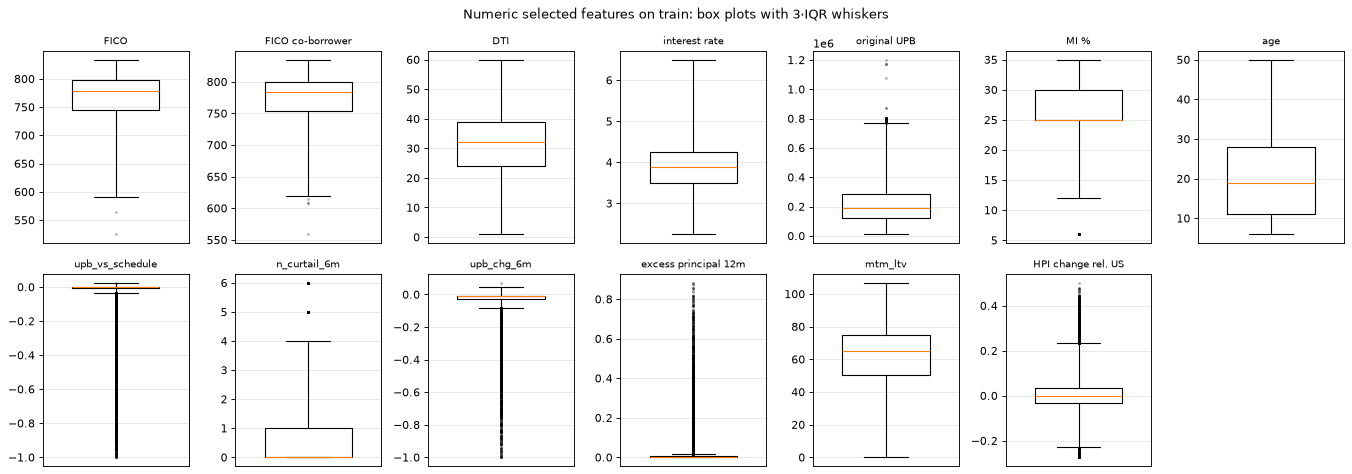

,min,p0.1,p1,median,p99,p99.9,max,far_outliers_pct,rate_outliers_pct,rate_inside_pct,implausible_rows
feature,,,,,,,,,,,
borrower_credit_score_at_origination,525.0000,623.0000,646.0000,779.0000,820.0000,825.0000,834.0000,0.0011,0.0000,0.1218,0.0000
co_borrower_credit_score_at_origination,559.0000,625.0000,655.0000,784.0000,820.0000,826.0000,835.0000,0.0037,0.0000,0.0565,0.0000
debt_to_income_dti,1.0000,5.0000,10.0000,32.0000,49.0000,50.0000,60.0000,0.0000,NaN,0.1221,0.0000
original_interest_rate,2.2500,2.6250,2.7500,3.8750,5.1250,5.5000,6.6250,0.0006,0.0000,0.1221,0.0000
original_upb,"11,000.0000","27,000.0000","43,000.0000","189,000.0000","572,000.0000","626,000.0000","1,202,000.0000",0.0161,0.0000,0.1221,0.0000
mortgage_insurance_percentage,6.0000,6.0000,6.0000,25.0000,35.0000,35.0000,40.0000,3.9553,0.0966,0.2140,0.0000
age,6.0000,6.0000,6.0000,19.0000,41.0000,42.0000,56.0000,0.0000,NaN,0.1221,0.0000
upb_vs_schedule,-1.0000,-0.8145,-0.3362,-0.0017,0.0034,0.0074,0.0286,9.7090,0.0397,0.1310,NaN
n_curtail_6m,0.0000,0.0000,0.0000,0.0000,6.0000,6.0000,6.0000,10.5970,0.0309,0.1329,0.0000


In [4]:
PLAUSIBLE = {"borrower_credit_score_at_origination": (300, 850), "co_borrower_credit_score_at_origination": (300, 850),
             "debt_to_income_dti": (0, 65), "original_interest_rate": (0, 15), "original_upb": (1, None),
             "mortgage_insurance_percentage": (0, 50), "age": (0, 480), "mtm_ltv": (0, 200), "n_curtail_6m": (0, 6)}
rows = []
for f in NUM:
    v = df[f].to_numpy().astype(float)
    ok = ~np.isnan(v)
    x, yy = v[ok], y[ok]
    q = np.percentile(x, [0, 0.1, 1, 25, 50, 75, 99, 99.9, 100])
    iqr = q[5] - q[3]
    if iqr > 0:
        out = (x < q[3] - 3 * iqr) | (x > q[5] + 3 * iqr)
        share, rate_out = 100 * out.mean(), (100 * yy[out].mean() if out.any() else np.nan)
        rate_in = 100 * yy[~out].mean()
    else:
        share = rate_out = rate_in = np.nan
    lo, hi = PLAUSIBLE.get(f, (None, None))
    bad = np.zeros(len(x), bool)
    if lo is not None: bad |= x < lo
    if hi is not None: bad |= x > hi
    rows.append({"feature": f, "min": q[0], "p0.1": q[1], "p1": q[2], "median": q[4], "p99": q[6], "p99.9": q[7], "max": q[8],
                 "far_outliers_pct": share, "rate_outliers_pct": rate_out, "rate_inside_pct": rate_in,
                 "implausible_rows": int(bad.sum()) if (lo is not None or hi is not None) else np.nan})
outl = pd.DataFrame(rows)
outl.to_csv(OUT / "eda_outliers.csv", index=False)

smp = df.sample(n=min(200_000, df.height), seed=SEED)
fig, axes = plt.subplots(2, 7, figsize=(17, 6))
for ax, f in zip(axes.flat, NUM):
    v = smp[f].drop_nulls().to_numpy()
    ax.boxplot(v, whis=3, flierprops={"markersize": 1.5, "alpha": 0.3}, widths=0.6)
    ax.set_title(short(f), fontsize=9); ax.set_xticks([])
axes.flat[-1].axis("off")
fig.suptitle("Numeric selected features on train: box plots with 3·IQR whiskers")
plt.tight_layout(); save(fig, "03_outliers"); plt.show()
outl.set_index("feature")

**EN. How to read.** No implausible values in the checked fields: FICO 525–834, DTI 1–60, interest rate 2.25–6.63 %, MTM LTV 0–108 %, age 6–56 months. Far outliers by Tukey's rule are almost only in the behaviour features: `n_curtail_6m` 10.6 % of rows, `upb_vs_schedule` 9.7 %, `excess_principal_12m` 7.4 %, `upb_chg_6m` 2.3 % — loans that pay ahead of schedule. This is not an error but a behaviour, and a safe one: the event rate on these rows is 0.03–0.05 % vs 0.13 % on the rest. The 58 rows with `upb_vs_schedule` ≈ −1 are loans almost repaid (balance ≤ $5,000), none with an event. The MI % outliers (4 %) are loans with the minimal 6 % coverage (LTV just above 80 %). **Nothing is clipped or removed**: CatBoost, XGBoost and LightGBM depend only on the order of values, the scorecard collects the tails into its end bins, and the MLP uses a quantile transform, so the tails do not dominate; removing them would remove real, safe borrowers.

**RU. Как читать.** Невозможных значений в проверенных полях нет: FICO 525–834, DTI 1–60, ставка 2,25–6,63 %, MTM LTV 0–108 %, возраст 6–56 месяцев. Дальние выбросы по правилу Тьюки почти только в поведенческих признаках: `n_curtail_6m` — 10,6 % строк, `upb_vs_schedule` — 9,7 %, `excess_principal_12m` — 7,4 %, `upb_chg_6m` — 2,3 %: это кредиты, которые гасят долг быстрее графика. Это не ошибка, а поведение, причём безопасное: доля событий в этих строках 0,03–0,05 % против 0,13 % в остальных. 58 строк с `upb_vs_schedule` ≈ −1 — почти погашенные кредиты (остаток ≤ 5 000 $), событий среди них нет. Выбросы MI % (4 %) — кредиты с минимальным покрытием 6 % (LTV чуть выше 80 %). **Ничего не обрезается и не удаляется**: CatBoost, XGBoost и LightGBM зависят только от порядка значений, скоринговая карта собирает хвосты в крайние корзины, MLP использует квантильное преобразование, поэтому хвосты не доминируют; удалив их, мы удалили бы реальных надёжных заёмщиков.

### 4. Distributions by event status / Распределения у кредитов с событием и без

**EN.** Distributions of the numeric selected features for rows with an event (Y1 = 1) and without (density, so the two groups are comparable despite the 0.12 % event rate; values beyond the 0.5 and 99.5 percentiles are left out of the plot for readability). Then the event rate by FICO band and by the categories of the categorical features (seller: the 10 largest).

**RU.** Распределения числовых отобранных признаков у строк с событием (Y1 = 1) и без него (плотность — чтобы группы были сравнимы при доле событий 0,12 %; значения за 0,5-м и 99,5-м процентилями не показаны для наглядности). Затем доля событий по группам FICO и по категориям категориальных признаков (продавец — 10 крупнейших).

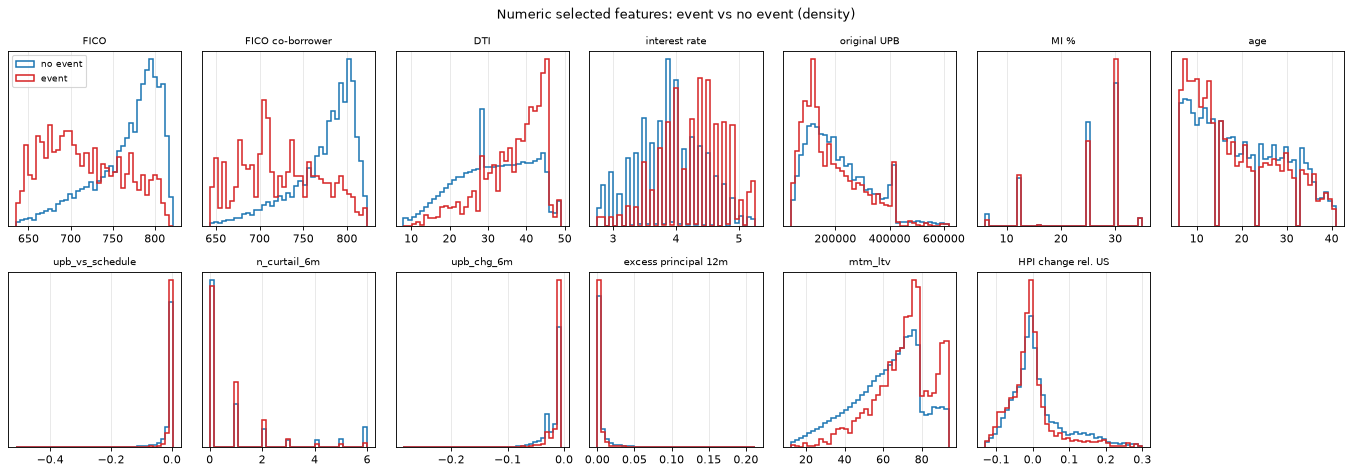

,median_no_event,median_event,mean_no_event,mean_event
feature,,,,
borrower_credit_score_at_origination,779.0000,705.0000,766.5692,711.7292
co_borrower_credit_score_at_origination,784.0000,714.0000,772.5174,719.5580
debt_to_income_dti,32.0000,39.0000,31.3959,36.5347
original_interest_rate,3.8750,4.3750,3.8833,4.2968
original_upb,"189,000.0000","152,000.0000","213,683.5204","186,587.3624"
mortgage_insurance_percentage,25.0000,30.0000,24.7280,25.4245
age,19.0000,16.0000,19.9790,18.6783
upb_vs_schedule,-0.0017,-0.0008,-0.0171,-0.0063
n_curtail_6m,0.0000,0.0000,1.0791,0.7166


In [5]:
fig, axes = plt.subplots(2, 7, figsize=(17, 6))
dist = []
for ax, f in zip(axes.flat, NUM):
    v = df[f].to_numpy().astype(float)
    ok = ~np.isnan(v)
    lo, hi = np.percentile(v[ok], [0.5, 99.5])
    bins = np.unique(np.linspace(lo, hi, 40)) if hi > lo else 10
    for cls, col, lab in ((0, "C0", "no event"), (1, "C3", "event")):
        x = v[ok & (y == cls)]
        x = x[(x >= lo) & (x <= hi)]
        ax.hist(x, bins=bins, density=True, histtype="step", color=col, label=lab, lw=1.4)
    ax.set_title(short(f), fontsize=9); ax.set_yticks([])
    dist.append({"feature": f, "median_no_event": np.median(v[ok & (y == 0)]), "median_event": np.median(v[ok & (y == 1)]),
                 "mean_no_event": v[ok & (y == 0)].mean(), "mean_event": v[ok & (y == 1)].mean()})
axes.flat[0].legend(fontsize=8); axes.flat[-1].axis("off")
fig.suptitle("Numeric selected features: event vs no event (density)")
plt.tight_layout(); save(fig, "04_distributions"); plt.show()
dist = pd.DataFrame(dist)
dist.to_csv(OUT / "eda_distributions.csv", index=False)
dist.set_index("feature")

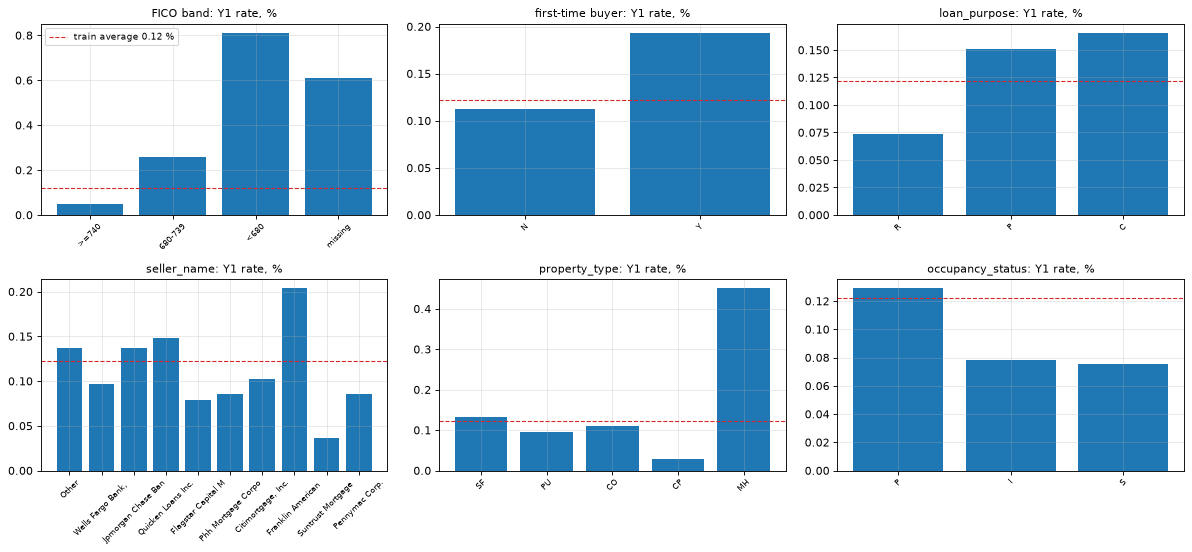

rows  events  rate_pct
feature                         category                                                            
FICO band                       >=740                                      1318035     650    0.0493
                                680-739                                     314321     806    0.2564
                                <680                                         77276     627    0.8114
                                missing                                        981       6    0.6116
first_time_home_buyer_indicator N                                          1501137    1684    0.1122
                                Y                                           209446     405    0.1934
                                missing                                         30       0    0.0000
loan_purpose                    R                                           706795     519    0.0734
                                P                                           621719     937    0.1507
                                C                                           382095     633    0.1657
                                U                                                4       0    0.0000
seller_name                     Other                                       765959    1048    0.1368
                                Wells Fargo Bank, N.A.                      381752     368    0.0964
                                Jpmorgan Chase Bank, National Association   122383     168    0.1373
                                Quicken Loans Inc.                           60212      89    0.1478
                                Flagstar Capital Markets Corporation         55920      44    0.0787
                                Phh Mortgage Corporation                     47711      41    0.0859
                                Citimortgage, Inc.                           45038      46    0.1021
                                Franklin American Mortgage Company           31916      65    0.2037
                                Suntrust Mortgage Inc.                       27440      10    0.0364
                                Pennymac Corp.                               18690      16    0.0856
property_type                   SF                                         1138944    1512    0.1328
                                PU                                          413160     389    0.0942
                                CO                                          141755     155    0.1093
                                CP                                           10092       3    0.0297
                                MH                                            6662      30    0.4503
occupancy_status                P                                          1483900    1914    0.1290
                                I                                           145681     114    0.0783
                                S                                            81032      61    0.0753

In [6]:
fico_band = (pl.when(pl.col("borrower_credit_score_at_origination").is_null()).then(pl.lit("missing"))
             .when(pl.col("borrower_credit_score_at_origination") < 680).then(pl.lit("<680"))
             .when(pl.col("borrower_credit_score_at_origination") < 740).then(pl.lit("680-739"))
             .otherwise(pl.lit(">=740")))
cat_rows = []
for f, expr in [("FICO band", fico_band), *[(c, pl.col(c).fill_null("missing")) for c in CATS]]:
    t = (df.group_by(expr.alias("category")).agg(pl.len().alias("rows"), pl.col("y1").sum().alias("events"),
                                                   (100 * pl.col("y1").mean()).alias("rate_pct"))
         .sort("rows", descending=True).to_pandas())
    if f == "seller_name":
        t = t.head(10)
    cat_rows.append(t.assign(feature=f))
cats = pd.concat(cat_rows, ignore_index=True)
cats.to_csv(OUT / "eda_category_rates.csv", index=False)

base = 100 * y.mean()
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (f, t) in zip(axes.flat, cats.groupby("feature", sort=False)):
    t = t[t["rows"] >= 500]
    ax.bar(t["category"].str.slice(0, 18), t["rate_pct"], color="C0")
    ax.axhline(base, color="C3", ls="--", lw=1, label=f"train average {base:.2f} %")
    ax.set_title(f"{short(f)}: Y1 rate, %", fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes.flat[0].legend(fontsize=8)
plt.tight_layout(); save(fig, "05_category_rates"); plt.show()
cats.set_index(["feature", "category"])

**EN. How to read.** Loans with an event differ as expected: median FICO 705 vs 779 (co-borrower 714 vs 784), DTI 39 vs 32 %, interest rate 4.38 vs 3.88 %, MTM LTV 73 vs 65 %, house prices since origination −1.0 vs −0.3 % relative to the US. They are smaller (original UPB 152 vs 189 thousand $) and younger (16 vs 19 months: the hazard of a mortgage peaks in the first years). The behaviour medians are close to 0 in both groups, but the means show that loans with an event prepay less (curtailments in 6 months 0.72 vs 1.08; excess principal 0.35 vs 0.75 % of the balance). By category: FICO < 680 has a rate of 0.81 %, 16 times the 0.05 % of FICO ≥ 740; first-time buyers 0.19 vs 0.11 %; refinancing 0.07 %, purchase 0.15 %, cash-out refinancing 0.17 %; manufactured housing 0.45 %, 3.4 times single-family homes; investors (0.08 %) and second homes (0.08 %) are **safer** than owner-occupiers (0.13 %) — the post-crisis selection of investors known from stage 2, which reverses in the stress periods (stage 3). Sellers range from 0.04 to 0.20 %.

**RU. Как читать.** Кредиты с событием отличаются так, как и ожидалось: медиана FICO 705 против 779 (у созаёмщика 714 против 784), DTI 39 против 32 %, ставка 4,38 против 3,88 %, MTM LTV 73 против 65 %, изменение цен на жильё с выдачи −1,0 против −0,3 % относительно США. Они меньше (сумма кредита 152 против 189 тыс. $) и моложе (16 против 19 месяцев: риск ипотечного кредита максимален в первые годы). Медианы поведенческих признаков близки к 0 в обеих группах, но средние показывают, что кредиты с событием реже гасят досрочно (частичных досрочных погашений за 6 месяцев 0,72 против 1,08; сверхплановое погашение 0,35 против 0,75 % остатка). По категориям: при FICO < 680 доля событий 0,81 % — в 16 раз выше, чем при FICO ≥ 740 (0,05 %); первая покупка жилья 0,19 против 0,11 %; рефинансирование 0,07 %, покупка 0,15 %, рефинансирование с выводом денег 0,17 %; сборные дома 0,45 % — в 3,4 раза выше, чем частные дома; инвесторы (0,08 %) и вторые дома (0,08 %) **надёжнее** живущих в своём доме (0,13 %) — известный с этапа 2 послекризисный отбор инвесторов, который в стресс-периодах меняет знак (этап 3). У продавцов доля событий от 0,04 до 0,20 %.

### 5. Before and after preprocessing / До и после предобработки

**EN.** What the preprocessing changes. (5.1) From monthly records to the panel: the counts of every build step (all vintages of the 15 % sample, from the panel build statistics; no outcomes are read) and then the train rows of the Y1 population. (5.2) Masked balance: Fannie Mae reports the current balance of a young loan as 0; we replace it with the contractual schedule balance — shown on the raw monthly records of vintage 2014Q1 (a train vintage). (5.3) WoE coding of the scorecard: the raw FICO and the 10 WoE bins that B0 receives instead. (5.4) Seller: the number of sellers and the share covered by the top 20 kept as categories.

**RU.** Что меняет предобработка. (5.1) От помесячных записей к панели: число строк на каждом шаге сборки (все поколения 15 %-й выборки, по статистике сборки панели; исходы не читаются), затем строки train популяции Y1. (5.2) Скрытый остаток долга: у молодого кредита Fannie Mae пишет текущий остаток 0; мы заменяем его остатком по графику платежей — показано на сырых помесячных записях поколения 2014Q1 (поколение train). (5.3) WoE-кодирование скоринговой карты: исходный FICO и 10 корзин WoE, которые получает B0. (5.4) Продавец: число продавцов и доля строк, которую покрывают 20 крупнейших, оставленные отдельными категориями.

In [7]:
stats = [json.loads(p.read_text()) for p in sorted((PANEL_DIR / "stats").glob("*.json"))]
st = pd.DataFrame(stats)
train_all = scan_panel().filter(pl.col("split_main") == "train")
tr = train_all.select(pl.len().alias("rows"), (pl.col("dpd") == 0).sum().alias("dpd0"), pl.col("pop_y1").sum().alias("pop"),
                      (pl.col("pop_y1") & pl.col("y1").is_not_null()).sum().alias("lab")).collect().row(0, named=True)
funnel = pd.DataFrame([
    ("all vintages", "monthly records of the sampled loans (incl. inserted missing months)", st["monthly_rows"].sum()),
    ("all vintages", "  of them inserted missing months", st["inserted_months"].sum()),
    ("all vintages", "quarter-end snapshots of live loans aged >= 6 months", st["snapshots_active"].sum()),
    ("all vintages", "panel rows (12-month outcome window inside the data)", st["panel_rows"].sum()),
    ("train", "panel rows on train dates (DPD 0-2 at t)", tr["rows"]),
    ("train", "current at t (DPD = 0)", tr["dpd0"]),
    ("train", "and no default before t = Y1 population", tr["pop"]),
    ("train", "with an observed label (used in this notebook)", tr["lab"]),
], columns=["scope", "step", "rows"])
funnel.to_csv(OUT / "eda_funnel.csv", index=False)
funnel

,scope,step,rows
0,all vintages,monthly records of the sampled loans (incl. in...,150033462
1,all vintages,of them inserted missing months,1402
2,all vintages,quarter-end snapshots of live loans aged >= 6 ...,43934120
3,all vintages,panel rows (12-month outcome window inside the...,40593542
4,train,panel rows on train dates (DPD 0-2 at t),1717549
5,train,current at t (DPD = 0),1711583
6,train,and no default before t = Y1 population,1710613
7,train,with an observed label (used in this notebook),1710613


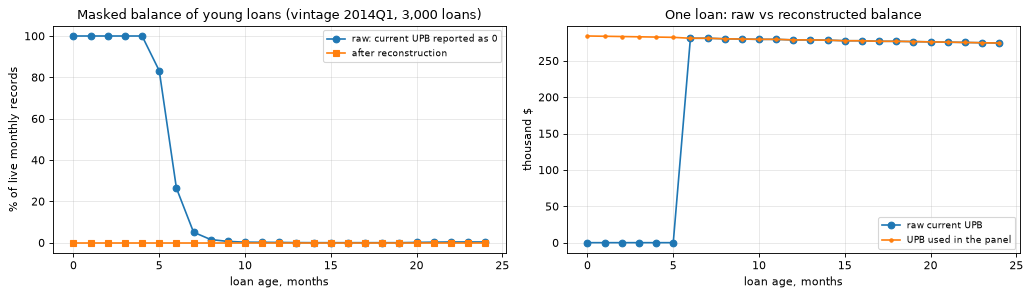

,age,raw_zero,after_zero,rows
0,0,1.0000,0.0000,2200
1,1,1.0000,0.0000,2839
2,2,1.0000,0.0000,2942
3,3,1.0000,0.0000,2956
4,4,1.0000,0.0000,2948
5,5,0.8319,0.0000,2926
6,6,0.2642,0.0000,2896
7,7,0.0505,0.0000,2871
8,8,0.0151,0.0000,2846
9,9,0.0060,0.0000,2817


In [8]:
perf = pl.read_parquet(INTERIM_DIR / "2014Q1" / "performance.parquet")
loans = pl.read_parquet(INTERIM_DIR / "2014Q1" / "loans.parquet")
ids = loans.select("loan_identifier").sample(n=3000, seed=SEED)
mon = prepare_monthly(perf.join(ids, on="loan_identifier"), loans.join(ids, on="loan_identifier"))
live = mon.filter(pl.col("zero_balance_code").is_null() & ~pl.col("inserted_month") & pl.col("age").is_between(0, 24))
mask = (live.group_by("age").agg((pl.col("current_actual_upb").fill_null(0) <= 0).mean().alias("raw_zero"),
                                (pl.col("upb").fill_null(0) <= 0).mean().alias("after_zero"), pl.len().alias("rows"))
        .sort("age").to_pandas())
mask.to_csv(OUT / "eda_upb_masking.csv", index=False)
ex_id = live.filter(pl.col("upb_masked") & (pl.col("age") == 3))["loan_identifier"][0]
ex = live.filter(pl.col("loan_identifier") == ex_id).sort("age").to_pandas()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(mask["age"], 100 * mask["raw_zero"], marker="o", label="raw: current UPB reported as 0")
ax[0].plot(mask["age"], 100 * mask["after_zero"], marker="s", label="after reconstruction")
ax[0].set_xlabel("loan age, months"); ax[0].set_ylabel("% of live monthly records"); ax[0].legend(fontsize=8)
ax[0].set_title("Masked balance of young loans (vintage 2014Q1, 3,000 loans)")
ax[1].plot(ex["age"], ex["current_actual_upb"].fillna(0) / 1e3, marker="o", label="raw current UPB")
ax[1].plot(ex["age"], ex["upb"] / 1e3, marker=".", label="UPB used in the panel")
ax[1].set_xlabel("loan age, months"); ax[1].set_ylabel("thousand $"); ax[1].legend(fontsize=8)
ax[1].set_title("One loan: raw vs reconstructed balance")
plt.tight_layout(); save(fig, "06_upb_masking"); plt.show()
del perf, mon, live; gc.collect()
mask.head(10)

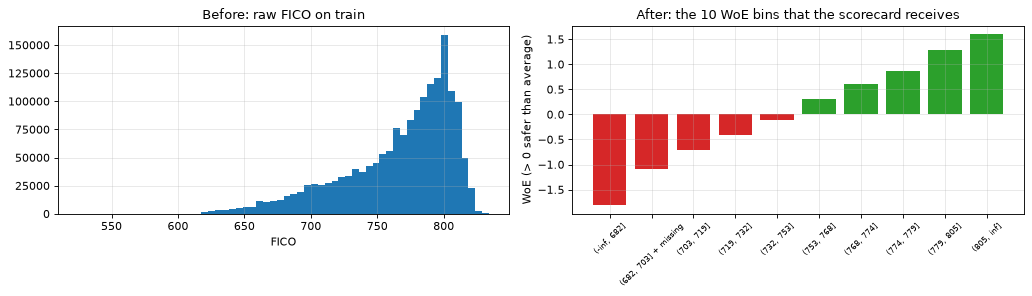

sellers on train: 39; the top 20 cover 97.1 % of rows, the rest go to 'other'


,woe,rows,rate_pct,bin
0,-1.8122,86612,0.7920,"(-inf, 682]"
1,-1.0888,85724,0.3978,"(682, 703] + missing"
2,-0.7023,85695,0.2252,"(703, 719]"
3,-0.4097,85608,0.1892,"(719, 732]"
4,-0.1081,172048,0.1128,"(732, 753]"
5,0.3029,178092,0.0820,"(753, 768]"
6,0.6006,89925,0.0778,"(768, 774]"
7,0.8742,87657,0.0513,"(774, 779]"
8,1.2840,597749,0.0341,"(779, 805]"
9,1.5997,241503,0.0199,"(805, inf]"


In [9]:
f = "borrower_credit_score_at_origination"
b = binners("y1")[f]
w = b.transform(df[f].to_numpy())
woe_tab = (pd.DataFrame({"woe": w, "y1": y}).groupby("woe").agg(rows=("y1", "size"), rate_pct=("y1", "mean")).reset_index())
woe_tab["rate_pct"] *= 100
labels = pd.DataFrame({"bin": b.labels, "key": np.round(np.asarray(b.woe, dtype=np.float32), 5)})
woe_tab = (woe_tab.assign(key=np.round(woe_tab["woe"].astype(np.float32), 5)).merge(labels, on="key", how="left")
           .drop(columns="key").sort_values("woe", ignore_index=True))
assert woe_tab["bin"].notna().all()
woe_tab.to_csv(OUT / "eda_woe_fico.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
v = df[f].drop_nulls().to_numpy()
ax[0].hist(v, bins=60, color="C0"); ax[0].set_title("Before: raw FICO on train"); ax[0].set_xlabel("FICO")
ax[1].bar(woe_tab["bin"], woe_tab["woe"], color=["C3" if x < 0 else "C2" for x in woe_tab["woe"]])
ax[1].set_title("After: the 10 WoE bins that the scorecard receives"); ax[1].tick_params(axis="x", rotation=45, labelsize=7)
ax[1].set_ylabel("WoE (> 0 safer than average)")
plt.tight_layout(); save(fig, "07_woe_fico"); plt.show()

sellers = df.group_by("seller_name").agg(pl.len().alias("rows")).sort("rows", descending=True)
top20 = sellers.head(20)["rows"].sum() / df.height
print(f"sellers on train: {sellers.height}; the top 20 cover {100 * top20:.1f} % of rows, the rest go to 'other'")
woe_tab

**EN. How to read.** **From monthly records to the panel:** 150.0 M monthly records of the sampled loans (1,402 missing months inserted as empty rows and flagged, never filled) → 43.9 M quarter-end snapshots of live loans aged ≥ 6 months → 40.6 M panel rows whose 12-month outcome window lies inside the data. On train dates: 1,717,549 rows (DPD 0–2 at t) → 1,711,583 current at t → 1,710,613 in the Y1 population (970 rows of loans after a first default removed). **Masked balance:** the raw current balance is 0 in 100 % of the live records at ages 0–4, 83 % at 5, 26 % at 6 and 5 % at 7; after the reconstruction no record has a zero balance. Without it the balance-change features would show a fake 100 % jump at the age when the balance first appears. **WoE coding:** the 234 distinct FICO values become 10 bins with WoE from −1.81 (FICO ≤ 682, event rate 0.79 %) to +1.60 (FICO > 805, 0.02 %), monotone, a 40-fold difference in risk; missing FICO goes into the bin 682–703. **Sellers:** 39 on train, including Fannie Mae's own "Other", which gathers small sellers (45 % of rows); the top 20 kept as categories cover 97.1 % of rows.

**RU. Как читать.** **От помесячных записей к панели:** 150,0 млн помесячных записей кредитов выборки (1 402 пропущенных месяца вставлены пустыми строками с флагом, ничем не заполнены) → 43,9 млн снимков на концах кварталов по действующим кредитам в возрасте ≥ 6 месяцев → 40,6 млн строк панели, у которых 12-месячное окно исхода лежит внутри данных. На датах train: 1 717 549 строк (DPD 0–2 на t) → 1 711 583 без просрочки на t → 1 710 613 в популяции Y1 (удалено 970 строк кредитов после первого дефолта). **Скрытый остаток долга:** в сырых данных текущий остаток равен 0 в 100 % записей действующих кредитов в возрасте 0–4 месяцев, в 83 % — в 5, в 26 % — в 6 и в 5 % — в 7; после восстановления нулевых остатков нет. Без этого признаки изменения остатка показали бы ложный скачок на 100 % в месяц, когда остаток впервые появляется. **WoE-кодирование:** 234 различных значения FICO превращаются в 10 корзин с WoE от −1,81 (FICO ≤ 682, доля событий 0,79 %) до +1,60 (FICO > 805, 0,02 %) — монотонно, разница в риске в 40 раз; пропуск FICO попадает в корзину 682–703. **Продавцы:** на train 39, включая категорию Fannie Mae «Other», в которую собраны мелкие продавцы (45 % строк); 20 крупнейших, оставленные отдельными категориями, покрывают 97,1 % строк.

**EN. Summary.** The train data are clean in the technical sense: no impossible values, and the missing values that matter are structural (no mortgage insurance, no co-borrower, young loans) and informative, so nothing is imputed. The outliers are real behaviour — repayment ahead of schedule, associated with lower risk — so nothing is clipped. The event is rare (0.12 %, one in 820 observations) and its rate depends on the vintage mix. The distributions agree with the economic expectations of stage 2 (lower FICO, higher DTI, interest rate and MTM LTV for loans with an event); the two exceptions known from stage 2 — investors are safer, younger loans are riskier — are visible already in the raw rates. Preprocessing changes three things: it builds quarterly snapshots from monthly records, reconstructs the masked balance of young loans and codes the features for the scorecard (WoE) and the MLP (quantile transform). Nothing in this analysis changes the selected features or the models.

**RU. Итог.** Данные train чистые в техническом смысле: невозможных значений нет, а значимые пропуски структурные (нет страховки, нет созаёмщика, молодой кредит) и информативные, поэтому ничего не заполняется. Выбросы — реальное поведение (погашение быстрее графика, связанное с меньшим риском), поэтому ничего не обрезается. Событие редкое (0,12 %, одно на 820 наблюдений), и его доля зависит от состава поколений. Распределения согласуются с экономическими ожиданиями этапа 2 (у кредитов с событием ниже FICO, выше DTI, ставка и MTM LTV); два исключения, известные с этапа 2, — инвесторы надёжнее, молодые кредиты рискованнее — видны уже в сырых долях. Предобработка меняет три вещи: собирает квартальные снимки из помесячных записей, восстанавливает скрытый остаток молодых кредитов и кодирует признаки для скоринговой карты (WoE) и MLP (квантильное преобразование). Ничто в этом анализе не меняет отобранные признаки и модели.